# B2 · Отказ от ответа при проверке утверждений - baseline

[Модель Qwen2.5-3B-Instruct](https://huggingface.co/Qwen/Qwen2.5-3B-Instruct) · [Данные VitaminC](https://huggingface.co/datasets/tals/vitaminc)

In [1]:
%pip install -q "transformers==5.17.0" "huggingface-hub>=1.5,<2" "accelerate==1.15.0" "bitsandbytes==0.50.2"


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from huggingface_hub import hf_hub_download
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

MODEL = "Qwen/Qwen2.5-3B-Instruct"
MODEL_REV = "aa8e72537993ba99e69dfaafa59ed015b17504d1"
DATA_REV = "be6febb761b0b2807687e61e0b5282e459df2fa0"
SEED = 42
N_CASES = 200
BATCH_SIZE = 2
LABELS = ["SUPPORTS", "REFUTES", "NOT ENOUGH INFO"]
OUT = Path("results") / "qwen3b_baseline"
OUT.mkdir(parents=True, exist_ok=True)
if not torch.cuda.is_available():
    raise RuntimeError("Для 4-битного запуска выберите ядро с доступом к NVIDIA CUDA.")
free, total = torch.cuda.mem_get_info()
print(f"{torch.cuda.get_device_name()} · свободно {free/2**30:.1f} из {total/2**30:.1f} ГиБ")

NVIDIA GeForce RTX 3070 Ti Laptop GPU · свободно 7.4 из 7.7 ГиБ


## Данные
Случайно выбираем целые группы `case_id`, чтобы сохранить связанные версии утверждений и источников. Порог выбираем на `dev`. Тестовые группы не пересекаются с группами настройки.

In [3]:
def load_split(filename):
    path = hf_hub_download("tals/vitaminc", filename, repo_type="dataset", revision=DATA_REV)
    cols = ["unique_id", "case_id", "claim", "evidence", "label"]
    return pd.read_json(path, lines=True, dtype=False)[cols]

def sample_cases(frame):
    ids = frame["case_id"].drop_duplicates().sample(n=N_CASES, random_state=SEED)
    return frame.loc[frame["case_id"].isin(ids)].reset_index(drop=True)

dev = sample_cases(load_split("dev.jsonl"))
test_pool = load_split("test.jsonl")
test = sample_cases(test_pool.loc[~test_pool.case_id.isin(dev.case_id)])
for name, frame in [("dev", dev), ("test", test)]:
    assert frame.label.isin(LABELS).all()
    print(name, len(frame), "примеров,", frame.case_id.nunique(), "групп")
display(dev.head(2))

dev.jsonl: reconstructing file:   0%|          |  0.00B / 32.9MB            

dev.jsonl: downloading bytes:           |  0.00B            

test.jsonl: reconstructing file:   0%|          |  0.00B / 28.7MB            

test.jsonl: downloading bytes:           |  0.00B            

dev 657 примеров, 200 групп
test 669 примеров, 200 групп


,unique_id,case_id,claim,evidence,label
0,5ee3932ac9e77c0008cc9adb_1,5ee3932ac9e77c0008cc9adb,The number of COVID-19 cases were less than 41...,"As of 24 March , more than 414,000 cases of CO...",NOT ENOUGH INFO
1,5ee3932ac9e77c0008cc9adb_2,5ee3932ac9e77c0008cc9adb,The number of COVID-19 cases were less than 41...,"As of 24 March , more than 415,000 cases of CO...",REFUTES


## Ответ и уверенность
Модель получает два поля на английском. Буквы A, B и C кодируют три класса. Берём логиты следующего токена, выбираем наиболее вероятную букву и вычисляем softmax по трём вариантам. Максимум — оценка уверенности. Правильная метка «недостаточно информации» считается полноценным ответом.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL, revision=MODEL_REV, padding_side="left")
quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                          bnb_4bit_compute_dtype=torch.float16)
model = AutoModelForCausalLM.from_pretrained(
    MODEL, revision=MODEL_REV, quantization_config=quant, device_map={"": 0},
    dtype=torch.float16,
).eval()

system = ("Judge the claim using only the evidence. Reply with exactly one letter. "
          "A = the evidence supports the claim. B = the evidence contradicts the claim. "
          "C = the evidence is insufficient to decide.")

def prompt(claim, evidence, layout):
    if layout == "text":
        body = f"Claim: {claim}\nEvidence: {evidence}"
    else:
        def escape(value):
            return value.replace("|", "\\|").replace("\n", "<br>")
        body = (f"| Field | Value |\n| --- | --- |\n| Claim | {escape(claim)} |\n"
                f"| Evidence | {escape(evidence)} |")
    return tokenizer.apply_chat_template(
        [{"role": "system", "content": system}, {"role": "user", "content": body}],
        tokenize=False, add_generation_prompt=True,
    )

prefix = prompt("Example claim", "Example evidence", "text")
prefix_ids = tokenizer.encode(prefix, add_special_tokens=False)
letter_ids = []
for letter in "ABC":
    ids = tokenizer.encode(prefix + letter, add_special_tokens=False)
    assert ids[:-1] == prefix_ids, f"{letter} должна добавлять ровно один токен"
    letter_ids.append(ids[-1])

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [ ]:
@torch.inference_mode()
def predict(frame, layout):
    logit_batches = []
    batches = []
    for start in tqdm(range(0, len(frame), BATCH_SIZE), desc=layout):
        rows = frame.iloc[start:start+BATCH_SIZE]
        prompts = [prompt(row.claim, row.evidence, layout) for row in rows.itertuples()]
        inputs = tokenizer(prompts, padding=True, add_special_tokens=False, return_tensors="pt").to(model.device)
        logits = model(**inputs, use_cache=False, logits_to_keep=1).logits[:, -1, letter_ids]
        logit_batches.append(logits.float().cpu().numpy())
        batches.append(logits.float().softmax(dim=-1).cpu().numpy())
    probs = np.concatenate(batches)
    result = frame[["unique_id", "case_id", "label"]].copy()
    result[["logit_A", "logit_B", "logit_C"]] = np.concatenate(logit_batches)
    result["layout"] = layout
    result[["p_A", "p_B", "p_C"]] = probs
    result["prediction"] = np.array(LABELS)[probs.argmax(axis=1)]
    result["confidence"] = probs.max(axis=1)
    result["error"] = result.prediction != result.label
    return result

## Предсказания модели
Сохраняем три логита до softmax и три вероятности. На тесте меняем только оформление. Одни и те же утверждение и источник записываем текстом или двумя строками Markdown-таблицы.

In [ ]:
cal = predict(dev, "text")
cal.to_csv(OUT / "dev_predictions.csv", index=False)

In [ ]:
for layout in ["text", "table"]:
    preds = predict(test, layout)
    preds.to_csv(OUT / f"test_{layout}_predictions.csv", index=False)

## Бейзлайн при разных целевых рисках
Этот раздел можно выполнить отдельно, начиная со следующей ячейки. Он читает сохранённые CSV из папки проекта и работает на CPU.

Исходная цель — 10%. После первого прогона добавлены цели 25% и 30%. Для каждой цели выбираем на dev порог с наибольшим охватом при допустимой доле ошибок. Ответ выдаётся при $s \geq \tau$. При равных оценках принимаем всю группу сразу. Порог $+\infty$ означает отказ на всех примерах.

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

OUT = Path("results/qwen3b_baseline")
targets = [0.10, 0.25, 0.30]
cal = pd.read_csv(OUT / "dev_predictions.csv")
test_preds = {layout: pd.read_csv(OUT / f"test_{layout}_predictions.csv")
              for layout in ["text", "table"]}

In [9]:
def risk_curve(predictions):
    groups = predictions.groupby("confidence").error.agg(["size", "sum"]).sort_index(ascending=False)
    curve = groups.cumsum().rename(columns={"size": "answered", "sum": "errors"})
    curve["coverage"] = curve.answered / len(predictions)
    curve["risk"] = curve.errors / curve.answered
    return curve

def choose_threshold(predictions, target):
    curve = risk_curve(predictions)
    feasible = curve.loc[curve.risk <= target]
    return float(feasible.index[-1]) if len(feasible) else np.inf

def evaluate(predictions, threshold):
    accepted = predictions.loc[predictions.confidence >= threshold]
    return dict(total=len(predictions), answered=len(accepted), errors=int(accepted.error.sum()),
                coverage=len(accepted)/len(predictions), risk=accepted.error.mean())

thresholds = {target: choose_threshold(cal, target) for target in targets}
dev_summary = pd.DataFrame([
    dict(target=target, threshold=tau, **evaluate(cal, tau))
    for target, tau in thresholds.items()
])
formats = {"target": "{:.0%}", "threshold": "{:.8f}", "risk": "{:.1%}", "coverage": "{:.1%}"}
display(dev_summary.style.format(formats, na_rep="—").hide(axis="index"))

target,threshold,total,answered,errors,coverage,risk
10%,inf,657,0,0,0.0%,—
25%,1.00000000,657,240,60,36.5%,25.0%
30%,0.99982905,657,487,146,74.1%,30.0%


## Проверка на тесте
Применяем каждый порог с dev к одним и тем же 669 примерам в двух форматах. Риск равен доле ошибок среди ответов, охват — доле принятых примеров. При нулевом охвате риск не определён и обозначен прочерком.

In [10]:
rows = []
for layout, preds in test_preds.items():
    rows.append(dict(layout=layout, mode="Ответ всем", target=np.nan, threshold=0.0,
                     **evaluate(preds, 0.0)))
    for target, tau in thresholds.items():
        rows.append(dict(layout=layout, mode="Порог по dev", target=target, threshold=tau,
                         **evaluate(preds, tau)))
summary = pd.DataFrame(rows)
summary.to_csv(OUT / "summary.csv", index=False)
display(summary.style.format(formats, na_rep="—").hide(axis="index"))

layout,mode,target,threshold,total,answered,errors,coverage,risk
text,Ответ всем,—,0.00000000,669,669,228,100.0%,34.1%
text,Порог по dev,10%,inf,669,0,0,0.0%,—
text,Порог по dev,25%,1.00000000,669,228,45,34.1%,19.7%
text,Порог по dev,30%,0.99982905,669,476,124,71.2%,26.1%
table,Ответ всем,—,0.00000000,669,669,242,100.0%,36.2%
table,Порог по dev,10%,inf,669,0,0,0.0%,—
table,Порог по dev,25%,1.00000000,669,217,45,32.4%,20.7%
table,Порог по dev,30%,0.99982905,669,440,124,65.8%,28.2%


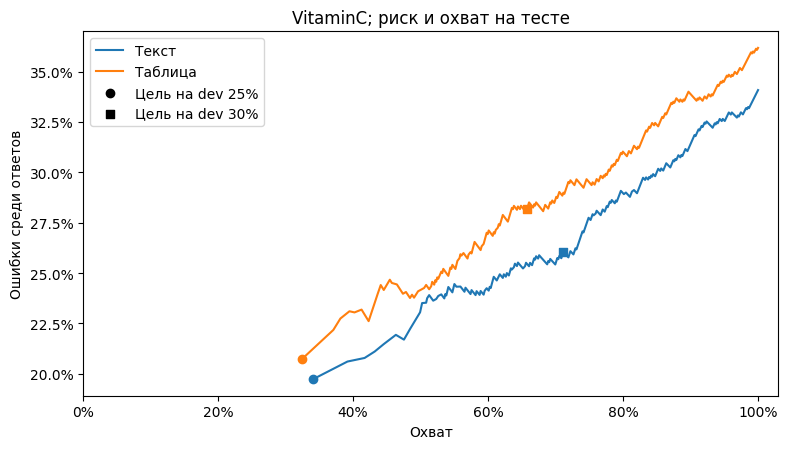

In [ ]:
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(8, 4.6))
markers = {0.25: "o", 0.30: "s"}
for layout, preds in test_preds.items():
    curve = risk_curve(preds)
    line, = ax.plot(curve.coverage, curve.risk, label={"text": "Текст", "table": "Таблица"}[layout])
    for target, tau in thresholds.items():
        point = evaluate(preds, tau)
        if point["answered"]:
            ax.scatter(point["coverage"], point["risk"], marker=markers.get(target, "^"),
                       color=line.get_color(), zorder=3)
for target, marker in markers.items():
    ax.scatter([], [], marker=marker, color="black", label=f"Цель на dev {target:.0%}")
ax.set(xlim=(0, 1.03), xlabel="Охват", ylabel="Ошибки среди ответов",
       title="VitaminC; риск и охват на тесте")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "risk_coverage.png", dpi=160)
plt.show()

## Выводы по исходной уверенности

При исходной цели 10% система в обоих форматах отказалась на всех примерах. На dev даже среди 240 ответов с уверенностью 1,0 было 60 ошибок (25%). Сравнить перенос риска при нулевом охвате нельзя.

Цели 25% и 30% добавили после первого прогона. В обоих форматах наблюдаемый тестовый риск остался ниже каждой цели. При переходе от текста к таблице риск немного вырос, а охват снизился.

## Температурная калибровка
Делим логиты на одно положительное число $T$ и снова считаем softmax. Выбираем $T$ по размеченным текстовым примерам dev, минимизируя логарифмическую потерю. Класс ответа сохраняется.

Случайно делим 200 групп dev пополам. На первой половине подбираем температуру, на второй — пороги для исходной и новой уверенности. Выше остаются результаты бейзлайна на полном dev.

Старые CSV содержат три положительные вероятности. Для них используем $\log p$: он совпадает с логитами с точностью до общей константы и округления. При полном новом запуске используем сохранённые исходные логиты.

In [ ]:
from scipy.optimize import minimize_scalar
from scipy.special import logsumexp, softmax

logit_cols = ["logit_A", "logit_B", "logit_C"]
prob_cols = ["p_A", "p_B", "p_C"]
labels = ["SUPPORTS", "REFUTES", "NOT ENOUGH INFO"]

def scores(frame):
    if all(col in frame for col in logit_cols):
        return frame[logit_cols].to_numpy()
    probs = frame[prob_cols].to_numpy()
    if (probs <= 0).any():
        raise ValueError("Для нулевых вероятностей нужны исходные логиты. Выполните полный прогон.")
    return np.log(probs)

fit_ids = cal.case_id.drop_duplicates().sample(frac=0.5, random_state=42)
fit = cal[cal.case_id.isin(fit_ids)]
tune = cal[~cal.case_id.isin(fit_ids)]
z = scores(fit)
y = pd.Categorical(fit.label, categories=labels).codes

def nll(log_t):
    scaled = z / np.exp(log_t)
    return (logsumexp(scaled, axis=1) - scaled[np.arange(len(y)), y]).mean()

temp = np.exp(minimize_scalar(nll, bounds=(-5, 5), method="bounded").x)
print(f"T = {temp:.3f}. Обучение: {len(fit)} примеров. Выбор порога: {len(tune)}.")

def calibrated(frame):
    confidence = softmax(scores(frame) / temp, axis=1).max(axis=1)
    return frame.assign(confidence=confidence)

T = 12.063. Обучение: 329 примеров. Выбор порога: 328.


## Насколько уверенность соответствует точности
Делим шкалу от 0 до 1 на 10 равных интервалов. Для каждого непустого интервала сравниваем среднюю уверенность с долей верных ответов. ECE — средний модуль разницы с учётом числа примеров. На графике идеальной калибровке соответствует диагональ.

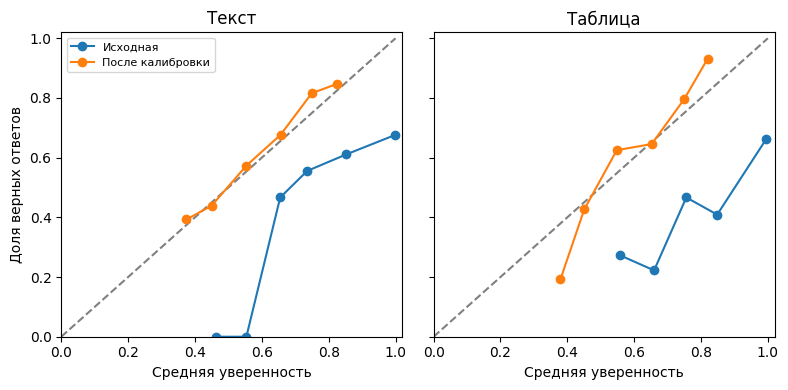

,format,method,ECE
0,text,Исходная,0.3172
1,text,После калибровки,0.0301
2,table,Исходная,0.3356
3,table,После калибровки,0.0474


In [ ]:
def reliability(frame):
    bins = pd.cut(frame.confidence, np.linspace(0, 1, 11), include_lowest=True)
    return frame.assign(correct=~frame.error).groupby(bins, observed=True).agg(
        confidence=("confidence", "mean"), accuracy=("correct", "mean"), count=("error", "size"))

fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True)
ece_rows = []
for ax, (layout, preds) in zip(axes, test_preds.items()):
    ax.plot([0, 1], [0, 1], "--", color="grey")
    for method, frame in [("Исходная", preds), ("После калибровки", calibrated(preds))]:
        bins = reliability(frame)
        ece = np.average(abs(bins.confidence - bins.accuracy), weights=bins["count"])
        ece_rows.append(dict(format=layout, method=method, ECE=ece))
        ax.plot(bins.confidence, bins.accuracy, "o-", label=method)
    ax.set(xlim=(0, 1.02), ylim=(0, 1.02), xlabel="Средняя уверенность",
           title={"text": "Текст", "table": "Таблица"}[layout])
axes[0].set_ylabel("Доля верных ответов")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()
display(pd.DataFrame(ece_rows).round(4))

## Риск и охват с 95% доверительными интервалами
При фиксированных порогах 2000 раз выбираем с возвращением целые тестовые группы case_id. Для двух форматов берём одинаковые группы. Границы интервала — квантили 2,5% и 97,5%. Интервалы учитывают разброс тестовой выборки при уже выбранных температуре и порогах. Прочерк означает, что ответов нет.

Итоговая таблица сохраняется в [calibration_summary.csv](qwen3b_baseline/calibration_summary.csv). Столбец `ece_all` рассчитан по всем примерам формата до отказа. Границы интервалов указаны в долях от 0 до 1.

In [ ]:
case_ids = sorted(test_preds["text"].case_id.unique())
rng = np.random.default_rng(42)
draws = rng.integers(len(case_ids), size=(2000, len(case_ids)))

def interval(values):
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.nan, np.nan
    low, high = np.quantile(values, [0.025, 0.975])
    return low, high

def bootstrap_row(frame, threshold):
    accepted = frame.confidence >= threshold
    counts = frame.assign(accepted=accepted, wrong=accepted & frame.error).groupby("case_id").agg(
        total=("error", "size"), answered=("accepted", "sum"), errors=("wrong", "sum"))
    total, answered, errors = counts.loc[case_ids].to_numpy()[draws].sum(axis=1).T
    risk = np.divide(errors, answered, out=np.full(len(draws), np.nan), where=answered > 0)
    risk_low, risk_high = interval(risk)
    coverage_low, coverage_high = interval(answered / total)
    return {**evaluate(frame, threshold), "risk_ci_low": risk_low, "risk_ci_high": risk_high,
            "coverage_ci_low": coverage_low, "coverage_ci_high": coverage_high}

ece_by_method = {(r["format"], r["method"]): r["ECE"] for r in ece_rows}
rows = []
for layout, preds in test_preds.items():
    methods = [("Ответ всем", preds, {None: 0.0}, "Исходная"),
               ("Бейзлайн, весь dev", preds, thresholds, "Исходная"),
               ("Исходная, ½ dev", preds, {t: choose_threshold(tune, t) for t in targets}, "Исходная"),
               ("С температурой, ½ dev", calibrated(preds),
                {t: choose_threshold(calibrated(tune), t) for t in targets}, "После калибровки")]
    for method, frame, cuts, calibration in methods:
        for target, cut in cuts.items():
            rows.append(dict(layout=layout, method=method, target=target, threshold=cut,
                             temperature=temp if calibration == "После калибровки" else 1.0,
                             ece_all=ece_by_method[layout, calibration], **bootstrap_row(frame, cut)))

intervals = pd.DataFrame(rows)
intervals.to_csv(OUT / "calibration_summary.csv", index=False)
percent_cols = ["target", "risk", "risk_ci_low", "risk_ci_high", "coverage", "coverage_ci_low", "coverage_ci_high"]
display(intervals.style.format({col: "{:.1%}" for col in percent_cols}, na_rep="—").hide(axis="index"))

layout,method,target,threshold,temperature,ece_all,total,answered,errors,coverage,risk,risk_ci_low,risk_ci_high,coverage_ci_low,coverage_ci_high
text,Ответ всем,—,0.000000,1.000000,0.317239,669,669,228,100.0%,34.1%,31.0%,37.3%,100.0%,100.0%
text,"Бейзлайн, весь dev",10.0%,inf,1.000000,0.317239,669,0,0,0.0%,—,—,—,0.0%,0.0%
text,"Бейзлайн, весь dev",25.0%,1.000000,1.000000,0.317239,669,228,45,34.1%,19.7%,15.2%,24.3%,30.1%,38.5%
text,"Бейзлайн, весь dev",30.0%,0.999829,1.000000,0.317239,669,476,124,71.2%,26.1%,22.8%,29.6%,66.9%,75.3%
text,"Исходная, ½ dev",10.0%,inf,1.000000,0.317239,669,0,0,0.0%,—,—,—,0.0%,0.0%
text,"Исходная, ½ dev",25.0%,inf,1.000000,0.317239,669,0,0,0.0%,—,—,—,0.0%,0.0%
text,"Исходная, ½ dev",30.0%,0.999842,1.000000,0.317239,669,474,122,70.9%,25.7%,22.5%,29.3%,66.6%,75.0%
text,"С температурой, ½ dev",10.0%,0.812048,12.063258,0.030077,669,53,9,7.9%,17.0%,8.2%,24.5%,5.5%,10.5%
text,"С температурой, ½ dev",25.0%,0.658520,12.063258,0.030077,669,325,69,48.6%,21.2%,17.4%,25.2%,44.0%,53.2%
text,"С температурой, ½ dev",30.0%,0.544364,12.063258,0.030077,669,488,130,72.9%,26.6%,23.4%,30.2%,68.6%,77.0%


**Вывод.** После калибровки ECE снизилась с 0,317 до 0,030 на тексте и с 0,336 до 0,047 на таблице. При цели 10% на тексте модель ответила на 7,9% примеров с риском 17,0%. Средняя уверенность стала ближе к точности, но выбранный порог превысил целевой риск на тексте.